### Dependencies


In [ ]:
import os

## Dependencies:
import warnings

import cv2

## Dependencies:
import matplotlib.pyplot as plt
from ezRay import MultiCoreExecutionTool

# interactive notebook
import numpy as np
import pandas as pd
import tifffile as tiff
import trackpy as tp
from ipywidgets import interact
from tqdm.notebook import tqdm

from tracking import introspect_frame, link_video

## Local utilities:
from util.pltStyler import pltStyler
from util.pyDialogue import pyDialogue as pyD

In [62]:
## Check if numba is enabled:
import trackpy.diag

trackpy.diag.performance_report()

Yes, but could it be faster?
FAST: numba is available and enabled (fast subnets and feature-finding).


### Grab Data & Median Image - Alternatively: generate Median

In [ ]:
# Currently supported file formats are ".tif"/".tiff"
filepath = pyD.askFILE('Choose the video file to analyze. Supported formats are .tif and .tiff.')
median_filepath = pyD.askFILE('Choose the median file to use as a reference for the video. If existant.')

# Extract the filename from the filepath to use in checkpoints
filename = os.path.basename(filepath).replace(".tif", "").replace(".tiff", "")
median_filename = os.path.basename(median_filepath).replace(".tif", "").replace(".tiff", "")

video_original = tiff.imread(filepath)

# collect the median file if it exists
try:
    median_image = tiff.imread(median_filepath)
except:
    median_image = None

if video_original.ndim == 2:
    video_original = np.expand_dims(video_original, axis=0)

video_length = video_original.shape[0]
print("Video length (t): ", video_length)
print("Image shape (y, x): ", video_original.shape[1:])

#### Checkpoint: Generate & Save Median Image

In [ ]:
## Check if the median image exists, if not, create it
# control
call_save_dialogue:bool = False

# create median image
if median_image is None:
    median_image = np.median(video_original, axis=0).astype(np.uint16)
median_image = median_image

# save median image
if call_save_dialogue:
    tiff.imwrite(pyD.askSAVEASFILE(), median_image)

### Median Filter

In [ ]:
## Subtract the median image from the video
# -> this is done to remove the static background from the video
# -> remove negative values by thresholding
# -> cast to uint8 for visualization and further processing

# filter tools
def threshold_image(image:np.ndarray, threshold:int)->np.ndarray:
    return np.where(image >= threshold, image, 0)

# cast to float
video_original = video_original.astype(np.float64)
median_image = median_image.astype(np.float64)

# subtract median image from video
video_subtracted = video_original - median_image

# threshold the subtracted video
# we do this to remove negative values
video_thresholded = threshold_image(image = video_subtracted,
                                    threshold = 0)

# cast to uint8
if np.max(video_thresholded) > 255:
    video_thresholded = (video_thresholded / np.max(video_thresholded) * 255)
video_thresholded = video_thresholded.astype(np.uint8)

### Interlude - Image processing

Blurring 2Sigma:   0%|          | 0/3059 [00:00<?, ?it/s]

Blurring 3Sigma:   0%|          | 0/3059 [00:00<?, ?it/s]

Text(0.5, 1.0, '3sig thresholded')

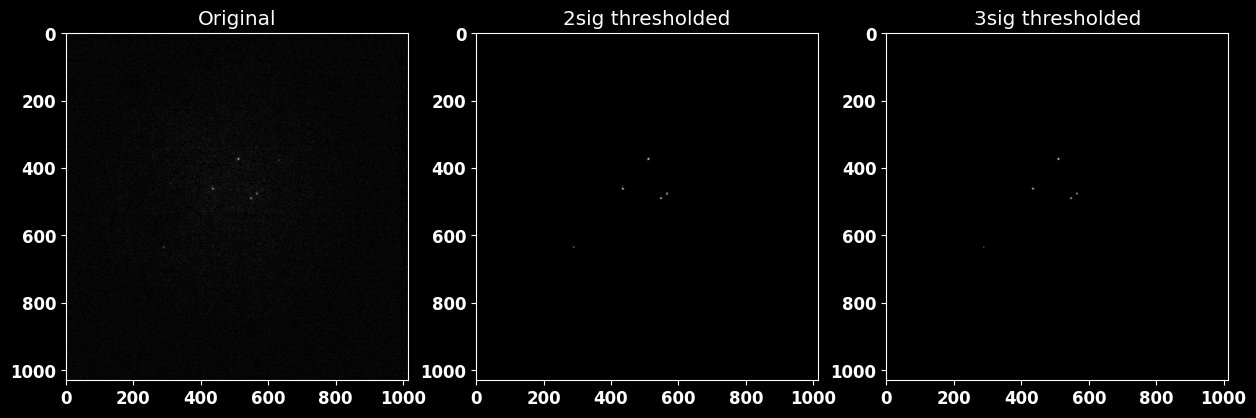

In [ ]:
## investigate thresholds #2
# we will assume that the particles are non-significant in the histogram of the image
# hence, we will assume the threshold by 2,3 standard deviations from the mean thereby characterizing the noise as main image with 95.9% and 99.7% confidence
# we will finally threshold the image by these values leaving only the significant particles

# get the stats
mean = np.mean(video_thresholded)
std = np.std(video_thresholded)

# STD thresholding
twoSigma = mean + 2*std
threeSigma = mean + 3*std

# threshold
twoSigmaThresholded = threshold_image(video_thresholded, np.round(twoSigma))
threeSigmaThresholded = threshold_image(video_thresholded, np.round(threeSigma))

# apply median filter
twoSigmaThresholded = np.stack([cv2.medianBlur(twSt, 5) for twSt in tqdm(twoSigmaThresholded, desc='Blurring 2Sigma')], axis=0)
threeSigmaThresholded = np.stack([cv2.medianBlur(thSt, 5) for thSt in tqdm(threeSigmaThresholded, desc='Blurring 3Sigma')], axis=0)

# plot side by side
pltStyler().enforece_stylesheet()

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(video_thresholded[0], cmap='gray')
axs[0].set_title('Original')
axs[1].imshow(twoSigmaThresholded[0], cmap='gray')
axs[1].set_title('2sig thresholded')
axs[2].imshow(threeSigmaThresholded[0], cmap='gray')
axs[2].set_title('3sig thresholded')

Equalizing 2Sigma:   0%|          | 0/3059 [00:00<?, ?it/s]

Equalizing 3Sigma:   0%|          | 0/3059 [00:00<?, ?it/s]

Text(0.5, 1.0, 'threeSigmaHistEq')

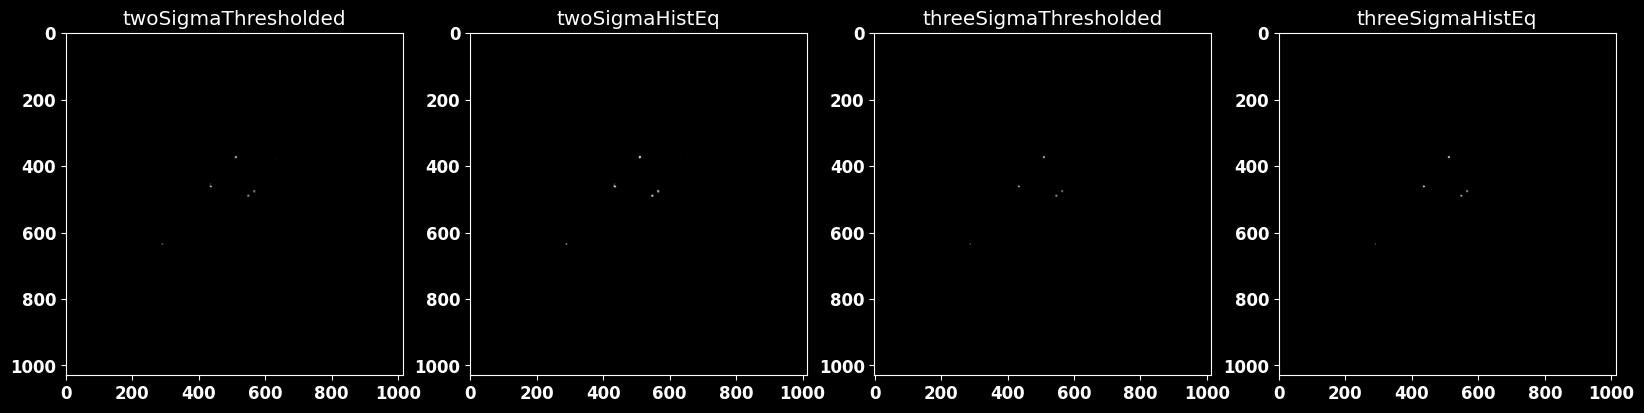

In [ ]:
## Histogram Equalization
# we will apply histogram equalization to the thresholded images to increase global contrast

# apply histogram equalization
twoSigmaHistEq = np.stack([cv2.equalizeHist(twSt) for twSt in tqdm(twoSigmaThresholded, desc='Equalizing 2Sigma')], axis=0)
threeSigmaHistEq = np.stack([cv2.equalizeHist(thSt) for thSt in tqdm(threeSigmaThresholded, desc='Equalizing 3Sigma')], axis=0)

# plot side by side
pltStyler().enforece_stylesheet()

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(twoSigmaThresholded[0], cmap='gray')
axs[0].set_title('twoSigmaThresholded')
axs[1].imshow(twoSigmaHistEq[0], cmap='gray')
axs[1].set_title('twoSigmaHistEq')
axs[2].imshow(threeSigmaThresholded[0], cmap='gray')
axs[2].set_title('threeSigmaThresholded')
axs[3].imshow(threeSigmaHistEq[0], cmap='gray')
axs[3].set_title('threeSigmaHistEq')

#### Checkpoint: Save PreProcessed Videos

In [ ]:
## Save denoised videos

call_save_dialogue:bool = True

#2sigma
if call_save_dialogue:
    tiff.imwrite(pyD.askSAVEASFILE(), twoSigmaHistEq)

#3sigma
if call_save_dialogue:
    tiff.imwrite(pyD.askSAVEASFILE(), threeSigmaHistEq)

### Tracking

In [3]:
## namespace & load video

# load the videos
twoSigmaHistEq = tiff.imread(pyD.askFILE("Please select the 2sigma denoised video."))
threeSigmaHistEq = tiff.imread(pyD.askFILE("Please select the 3sigma denoised video."))

# choose the video to analyze
video:np.ndarray = twoSigmaHistEq

In [6]:
# Set video ranges. If you want to select the whole video, 
# set start_frame = 0 and end_frame = video_length
start_frame = 0
end_frame = len(video)

# crop parameters;
# you can specify the region of interest (ROI) to crop the video
# if you want to crop the whole video; default values are set to 0
# for the offset and to the video shape for the size
x, y = 0, 0
width, height = video.shape[2], video.shape[1]

video_section = video[start_frame:end_frame, y:y+height, x:x+width]
if video_section.shape[0] == 0:
    raise ValueError("Selected video range is empty. Please select a valid range.")
print("Selected video shape: ", video_section.shape)

Selected video shape:  (3059, 1030, 1014)


#### Interlude: Parameter optimization

In [7]:
def calculate_diameter(micron_per_pixel: float, fwhm: float) -> int:
    """ Calculates the diameter of the bead in pixels.
    The diameter is calculated as the nearest odd integer to the full width half maximum (FWHM) of the fitted Gaussian.

    Args:
        micron_per_pixel (float): effective pixel size in microns.
        fwhm (float): full with half maximum of fitted Gaussian in microns.

    Returns:
        float: Diameter of the bead in pixels.
    """
    diameter = int(round(fwhm / micron_per_pixel))
    if diameter % 2 != 0:
        diameter += 1
    return diameter + 1

# physical parameters
micron_per_pixel = 57e-9 * 1e6    # image effective pixel size in microns
FWHM = 300e-9 * 1e6               # full width at half maximum in microns

# positional arguments
diameter = calculate_diameter(micron_per_pixel, FWHM)

# keyword arguments
locate = {
    "invert": False,            # wheather to invert the pixel values of the input frame; this is useful for dark beads on a bright background
    "minmass": 1,               # minimum integrated brightness;
    "separation": diameter + 1  # minimum separation distance between features
}

print(f"Calculated feature diameter: {diameter} pixels")

Calculated feature diameter: 7 pixels


In [12]:
# we set the 'minmass' parameter to 0 to detect all particles
locate['minmass'] = 0.95

# we select a volume to analyze
selected_clip = video[:10]
selected_frame = selected_clip[0]

# introspect the volume to find a suitable 'minmass' value;
# we set as target the number of particles to be detected
# and the minimum increase step of 'minmass' to reach the target
target = 5
minmass_step = 0.05

# current number of found particles,
# initialized to infinity
current = np.inf

pbar = tqdm(total=100)
pbar.desc = f"minmass: {locate['minmass']}, detected: {current}"

# we iterate until we reach the target number of particles
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    while current > target:
        current = introspect_frame(selected_frame, diameter, **locate)
        locate['minmass'] = round(locate['minmass'] + minmass_step, 2)
        pbar.update()
        pbar.desc = f"minmass: {locate['minmass']}, detected: {current}"
print(f"Final minmass value: {locate['minmass']}")

## annotate the particles in the video for the selected clip to check the tracking
@interact(t=(0, len(selected_clip)-1, 1))
def plot(t = 0):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        df : pd.DataFrame = tp.locate(selected_clip[t], diameter, **locate)
        tp.annotate(df, selected_clip[t])
        plt.show()

  0%|          | 0/100 [00:00<?, ?it/s]

Final minmass value: 1.0


interactive(children=(IntSlider(value=0, description='t', max=9), Output()), _dom_classes=('widget-interact',)…

#### Locate Particles across Frames

In [ ]:
## Multiprocessing
# we will use multiprocessing to speed up the tracking process
# if your system does not support multiprocessing, you can set the number of workers to 1


## We set a few parameters for the multiprocessing instance
# -> 'num_cpu' is the number of logical CPU cores to use
# -> 'num_gpu' is the number of GPU devices to use, in our case we will not use any GPU
# -> 'launch_dashboard' is a boolean flag to launch the Dask dashboard
# -> 'sleeptime' is an artificial time-delay that affects the multiprocessing monitoring
specs:dict = {
    'num_cpu': 12,
    'num_gpu': 0,
    'launch_dashboard': True,
    'sleeptime': 0
    }

## Convert our video and instructions into readable runtime data
RuntimeData:dict = {ID: {'raw_image': frame, 'diameter': diameter} | locate for ID,frame in enumerate(video)}

In [ ]:
## We create a MultiCoreExecutionTool instance
#-> We can either directly provice the RuntimeData or use the 'update_data' method to add data
MultiCore: MultiCoreExecutionTool = MultiCoreExecutionTool(RuntimeData, **specs)

2025-02-13 18:08:57,132	INFO worker.py:1832 -- Started a local Ray instance. View the dashboard at 127.0.0.1:8266 


In [33]:
## Let's schedule the locate_across_time function to be executed
MultiCore.run(tp.locate)

Scheduling Workers:   0%|          | 0/3059 [00:00<?, ?it/s]

Workers:   0%|          | 0/3059 [00:00<?, ?it/s]

CPU usage:   0%|          |

RAM usage:   0%|          |

True

In [69]:
## Extract Results
RuntimeResults = MultiCore.get_results()

## add the frame number to the results
for ID, result in RuntimeResults.items():
    result['result']['frame'] = ID

# package the results into a DataFrame and reset the index
particle_locs_per_frame = pd.DataFrame.reset_index(
    pd.concat(
        [pd.DataFrame.reset_index(v['result'], drop=True) for v in RuntimeResults.values()]),
    drop=True
    )

# take a look
particle_locs_per_frame.tail()

,y,x,mass,size,ecc,signal,raw_mass,ep,frame
22538,492.000000,514.623361,296.502801,1.306443,0.165874,43.821630,580.0,0.0,3058
22539,538.764602,402.507459,1397.697947,1.983816,0.085894,73.507250,5714.0,0.0,3058
22540,568.646993,490.595490,1269.413660,1.947316,0.042157,73.153850,5306.0,0.0,3058
22541,581.653217,265.751908,648.136039,1.400459,0.124722,80.928655,1572.0,0.0,3058
22542,736.321596,351.616197,301.097004,1.369092,0.132932,40.994428,633.0,0.0,3058


In [85]:
## Link the particles across frames
link_params = {
    "search_range": diameter + 1,  # maximum distance features can move between frames
    "memory": 0,                   # number of frames a feature can disappear and reappear
    "adaptive_stop": 0.2,          # stop linking features if probability drops below this value
    "adaptive_step": 0.95          # Reduce search_range by multiplying it by this factor.
}

# some additonal params
t_column:str = 'frame' # the column name for the time
min_length:int = 0     # minimum length of a track

# link the particles
linked_particles = link_video(particle_locs_per_frame, t_column, min_length, **link_params)

Frame 3058: 11 trajectories present.


In [87]:
# count how many tracks are present in the DataFrame
print("Number of tracks found:", len(linked_particles["particle"].unique()))

# we set the value `threshold` as the minimum number of frames a particle
# must be present in the DataFrame to be considered a valid particle; you can
# adjust this value to filter out short tracks according to your needs
threshold_filter = 50

linked_particles_filtered = tp.filter_stubs(linked_particles, threshold=threshold_filter)

# count how many tracks are present in the filtered DataFrame
print("Number of tracks after filtering:", len(linked_particles_filtered["particle"].unique()))

Number of tracks found: 2835
Number of tracks after filtering: 82


### Show Results - Plotly

In [89]:
import plotly.graph_objects as go

In [194]:
# the original dataframe offers the coordinates in pixels;
# we can convert them to microns by multiplying them by the
# micron per pixel value;
unit = "μm"

df_microns = linked_particles_filtered.copy()

if unit == "μm":
    # we convert the x, y and z columns to microns
    df_microns["x"] *= micron_per_pixel
    df_microns["y"] *= micron_per_pixel
else:
    # overriding the unit to pixels
    unit = "px"

# Create a color map
colors = plt.cm.viridis(np.linspace(0, 1, len(df_microns['particle'].unique())))

fig = go.Figure()

for i, particle in enumerate(df_microns['particle'].unique()):
    df_particle = df_microns[df_microns['particle'] == particle]
    color = 'rgb'+str(tuple(int(c*255) for c in colors[i][:3]))  # convert to integer and then to string
    fig.add_trace(go.Scatter(x=df_particle['x'], y=df_particle['y'], 
                               mode='lines', 
                               line=dict(color=color, width=2),
                               name=f'Particle {particle}',
                               legendgroup=i,
                               showlegend=False),)

    # Highlight the starting point
    start = df_particle.iloc[0]
    fig.add_trace(go.Scatter(x=[start['x']], y=[start['y']],
                               mode='markers', #markers+text
                               marker=dict(size=5, color='red', symbol='cross'),  # larger, green marker
                               name=f'Particle {particle}',
                               text = f'Start of Particle {particle}',
                               hoverinfo='text',
                               textfont=dict(size=12, family='Helvetica', color='white'),
                               legendgroup=i))

fig.update_layout(scene=dict(xaxis=dict(
                                 backgroundcolor="rgb(200, 200, 230)",
                                 gridcolor="white",
                                 showbackground=True,
                                 zerolinecolor="white",),
                             yaxis=dict(
                                 backgroundcolor="rgb(230, 200, 230)",
                                 gridcolor="white",
                                 showbackground=True,
                                 zerolinecolor="white"),
                             ),
                font = dict(family="Helvetica",
                            size=18,
                            color="white"), 
                title="<b>2D trajectories</b>",
                xaxis_title=f"<b>X [{unit}]</b>", 
                yaxis_title=f"<b>Y [{unit}]</b>",
                plot_bgcolor='black',
                paper_bgcolor='black',
                scene_bgcolor='black',
                width=900,
                height=700,
                margin=dict(r=20, b=20, l=20, t=50))

fig.show()

In [82]:
linked_particles

,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
0,384.022059,493.464084,1262.140543,1.774234,0.102732,91.019751,3992.0,0.000000,46,29
1,382.368657,493.282275,1473.874129,1.893681,0.067598,88.703777,5583.0,0.000054,47,29
2,385.693425,492.340803,1458.781237,1.912581,0.060528,84.056836,5215.0,0.000000,48,29
3,383.546316,489.505350,1142.482624,1.975314,0.104913,67.759593,4868.0,0.000000,49,29
4,382.319322,492.598151,1404.174766,1.972132,0.067828,76.945316,5668.0,0.000000,50,29
...,...,...,...,...,...,...,...,...,...,...
2868,575.524817,502.963114,1308.130193,1.920300,0.134937,77.700166,5215.0,0.000000,3015,2555
2869,576.844018,502.806989,1481.943983,2.009121,0.086313,70.307456,5762.0,0.000000,3016,2555
2870,577.408321,498.430044,1187.913088,1.928299,0.048344,71.729656,5106.0,0.000000,3017,2555
2871,578.069048,500.423545,1368.123992,1.944739,0.110108,76.006888,5134.0,0.000000,3018,2555
